# Sprint 4 — MegaMarket: prioridad de despacho con lógica difusa

Jacobo Argote, Andrés Cardona, Miguel Valencia y Juan José Gil

##**CÓDIGO GENERADO CON CLAUDE**

## De dónde venimos y qué agregamos

En el **Sprint 2** el sistema experto de logística decidía quién entra en la ruta de la semana con reglas
binarias: R1 (el mercaderista vio stock bajo), R2 (sin visita y más de 15 días sin entrega), R3 (queja urgente),
R4 y R5 (vetos por flete y por precio). El problema de una regla binaria es el **umbral duro**: con R2, un cliente
con 15 días sin entrega no entra y uno con 16 sí, aunque en la práctica son casi el mismo caso. Y todos los clientes
que entran con la misma etiqueta (por ejemplo BAJA) quedan empatados.

En este sprint reemplazamos la parte **gradual** de esa decisión por un **sistema de inferencia difusa** (Mamdani):

| Pieza | Sprint 2 (binario) | Sprint 4 (difuso) |
|---|---|---|
| Vetos R4 (flete > 4 %) y R5 (PVP) | Restricción dura | **Se mantienen duros**: son políticas, no grados |
| Queja urgente R3 | Prioridad ALTA | **Se mantiene**: prioridad 100 |
| Stock, rotación, días sin entrega, flete | Reglas SI-ENTONCES con umbrales | **Grados de pertenencia** y reglas difusas D1–D11 |
| Salida | Incluir / no incluir + ALTA/MEDIA/BAJA | **Prioridad 0–100** y su etiqueta lingüística |

La salida difusa se entrega a `recorrido_completo` del Sprint 1 (A*), igual que antes la salida del sistema experto.

## Parte 0 — Datos y lo heredado de los sprints anteriores

Todo vive en el repositorio del proyecto: los CSV en `data/` y el código de los sprints anteriores en el paquete
`megamarket/` (A*, sistema experto, AG). Si el notebook se abre en Colab, la celda clona el repositorio.

In [1]:
# =============================================================================
# 0. PREPARAR EL ENTORNO (Colab o local)
# =============================================================================
import os, sys

REPO = "https://github.com/jacoal1234-creator/megamarket-fund-ia"   # <- reemplazar por la URL real del repositorio

if os.path.exists("../data/difuso_reglas.csv"):          # corriendo desde notebooks/ en el repo
    RAIZ = os.path.abspath("..")
elif os.path.exists("data/difuso_reglas.csv"):           # corriendo desde la raíz del repo
    RAIZ = os.path.abspath(".")
else:                                                    # Colab: se clona el repositorio
    os.system(f"git clone -q {REPO}")
    RAIZ = os.path.abspath("megamarket-fund-ia")
sys.path.insert(0, RAIZ)
DATA = os.path.join(RAIZ, "data")
print("Datos en:", os.path.relpath(DATA))

Datos en: ../data


In [2]:
# =============================================================================
# 1. LIBRERÍAS, SEMILLA Y LO HEREDADO (sin cambios de lógica)
# =============================================================================
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)

from megamarket.rutas import ruta_de_la_semana, RUTAS                 # Sprint 1: A* + recorrido_completo
from megamarket.experto import vetos, decidir_clientes_de_la_ruta      # Sprint 2: R4/R5 y el motor binario
from megamarket.datos import cargar_memoria_logistica, cargar_clientes

MEMORIA_TRABAJO = cargar_memoria_logistica()     # data/memoria_trabajo_logistica.csv
CLIENTES = cargar_clientes()                     # data/clientes.csv (ruta y rotación, hechos fijos)
pd.read_csv(os.path.join(DATA, "memoria_trabajo_logistica.csv"))

,cliente,visita_mercaderista_disponible,mercaderista_reporta_stock_bajo,dias_desde_ultima_entrega,queja_urgente,precio_actualizado_en_punto_de_venta,valor_factura_pedido,costo_flete_estimado
0,Fruver del Río,Sí,Sí,10,No,Sí,850000,50000
1,Fruver Visitación,Sí,No,20,No,Sí,600000,15000
2,Five Sisters,No,No hubo visita,18,No,Sí,700000,20000
3,Supermercado Merka 10,Sí,No,8,Sí,Sí,500000,15000
4,Hotel Four Points,Sí,No,5,No,Sí,1200000,18000
5,Mercados Verona,Sí,Sí,22,No,Sí,300000,10000
6,EAFIT La Bodeguita,No,No hubo visita,6,Sí,Sí,900000,20000
7,Redetrans,Sí,Sí,12,No,No,400000,13000
8,CEDI Vaquita Itagüí,Sí,Sí,14,No,Sí,2500000,40000
9,CEDI Euro La Estrella,No,No hubo visita,25,No,Sí,1800000,95000


## Parte 1 — Variables lingüísticas y funciones de pertenencia

Cada variable de entrada se describe con **conjuntos difusos**. Un valor no "es" o "no es" Vencido: pertenece a
Vencido con un grado entre 0 y 1. Usamos funciones **trapezoidales** (la triangular es un trapecio con `b = c`).

| Variable | Universo | Conjuntos | De dónde sale el dato |
|---|---|---|---|
| `senal_stock` | 0–1 | Sin alerta / Incierto / Bajo | Reporte del mercaderista: No = 0, **No hubo visita = 0,5**, Sí = 1 |
| `rotacion` | 1–5 | Baja / Media / Alta | Rotación del producto en el punto (baja = 1, media = 3, alta = 5) |
| `dias_desde_ultima_entrega` | 0–30 | Reciente / Normal / Vencido | Memoria de trabajo |
| `flete_pct` | 0–4 % | Bajo / Medio / Alto | Flete ÷ factura (por encima de 4 % ya lo vetó R4) |
| `prioridad` (salida) | 0–100 | Baja / Media / Alta | — |

**Supuesto a defender:** "No hubo visita" se codifica como 0,5 porque representa incertidumbre, no un stock
intermedio. Es justo el tipo de dato que la lógica binaria no sabía manejar (por eso existía R2 como respaldo).

Los parámetros de cada trapecio están en `data/difuso_conjuntos.csv`, no en el código.

In [3]:
# =============================================================================
# 2. FUNCIONES DE PERTENENCIA
# =============================================================================
def trapecio(x, a, b, c, d):
    """Grado de pertenencia de x al trapecio (a, b, c, d).
    Sube de a a b, vale 1 entre b y c, baja de c a d. Si a == b (o c == d)
    el lado es vertical: es un 'hombro' en el borde del universo."""
    x = np.asarray(x, dtype=float)
    subida = np.ones_like(x) if b == a else np.clip((x - a) / (b - a), 0, 1)
    bajada = np.ones_like(x) if d == c else np.clip((d - x) / (d - c), 0, 1)
    grado = np.minimum(subida, bajada)
    return np.where((x < a) | (x > d), 0.0, grado)


conjuntos_df = pd.read_csv(os.path.join(DATA, "difuso_conjuntos.csv"))
CONJUNTOS = {}
for _, f in conjuntos_df.iterrows():
    CONJUNTOS.setdefault(f["variable"], {})[f["conjunto"]] = (f["a"], f["b"], f["c"], f["d"])

UNIVERSO = {"senal_stock": (0, 1), "rotacion": (1, 5), "dias_desde_ultima_entrega": (0, 30),
            "flete_pct": (0, 4), "prioridad": (0, 100)}
VARIABLES_ENTRADA = ["senal_stock", "rotacion", "dias_desde_ultima_entrega", "flete_pct"]
conjuntos_df

,variable,conjunto,a,b,c,d,descripcion
0,dias_desde_ultima_entrega,Reciente,0.0,0.0,5.0,10.0,Se le entregó hace poco
1,dias_desde_ultima_entrega,Normal,7.0,12.0,12.0,17.0,Ciclo de reposición habitual
2,dias_desde_ultima_entrega,Vencido,14.0,20.0,30.0,30.0,Lleva mucho tiempo sin entrega
3,flete_pct,Bajo,0.0,0.0,1.5,2.5,Flete holgado frente al tope del 4%
4,flete_pct,Medio,1.5,2.5,2.5,3.5,Flete razonable
5,flete_pct,Alto,2.5,3.5,4.0,4.0,Flete cerca del tope del 4%
6,senal_stock,Sin alerta,0.0,0.0,0.2,0.5,El mercaderista visitó y el stock está bien
7,senal_stock,Incierto,0.2,0.5,0.5,0.8,No hubo visita: no se sabe
8,senal_stock,Bajo,0.5,0.8,1.0,1.0,El mercaderista reportó stock bajo
9,rotacion,Baja,1.0,1.0,1.5,3.0,Rotación baja en el punto de venta


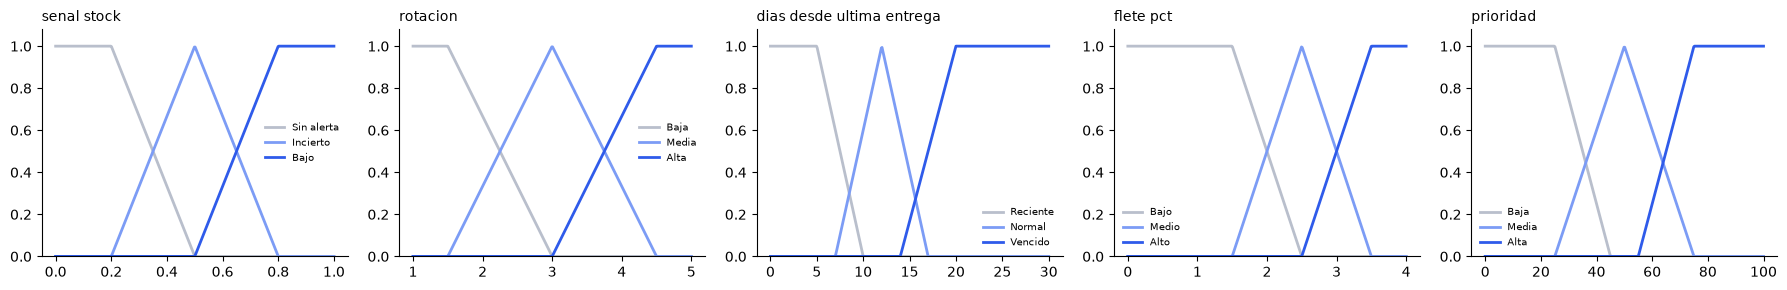

In [4]:
# @title
# CÓDIGO DE APOYO VISUAL (oculto): funciones de pertenencia de cada variable
COLORES = {0: "#b9bfcc", 1: "#7c9cf5", 2: "#2f5bea"}
fig, ejes = plt.subplots(1, 5, figsize=(18, 3))
for ax, var in zip(ejes, VARIABLES_ENTRADA + ["prioridad"]):
    x = np.linspace(*UNIVERSO[var], 400)
    for i, (nombre, params) in enumerate(CONJUNTOS[var].items()):
        ax.plot(x, trapecio(x, *params), color=COLORES[i], lw=2, label=nombre)
    ax.set_title(var.replace("_", " "), loc="left", fontsize=10)
    ax.set_ylim(0, 1.08); ax.legend(fontsize=7, frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## Parte 2 — Base de reglas difusas

Las reglas traducen el conocimiento del mercaderista y de la gerencia. Siguen la misma lógica de negocio del
Sprint 2, pero ahora con grados: por ejemplo, **D10** mantiene el principio de que la observación directa del
mercaderista manda sobre el tiempo, y **D11** baja la prioridad cuando el flete se acerca al tope del 4 %
(antes solo existía el veto). Viven en `data/difuso_reglas.csv`; `*` significa "no importa".

In [5]:
# =============================================================================
# 3. BASE DE REGLAS (desde CSV)
# =============================================================================
reglas_df = pd.read_csv(os.path.join(DATA, "difuso_reglas.csv"))
REGLAS = [f.to_dict() for _, f in reglas_df.iterrows()]
reglas_df

,regla,senal_stock,rotacion,dias_desde_ultima_entrega,flete_pct,prioridad,explicacion
0,D1,Bajo,Alta,*,*,Alta,Stock bajo donde el producto rota rápido: hay ...
1,D2,Bajo,Media,*,*,Media,Stock bajo con rotación media
2,D3,Bajo,Baja,*,*,Baja,Stock bajo pero el producto casi no rota
3,D4,Bajo,*,Vencido,*,Alta,Stock bajo y mucho tiempo sin entrega
4,D5,Incierto,Alta,Vencido,*,Alta,Sin visita y mucho tiempo sin entrega en un pu...
5,D6,Incierto,Media,Vencido,*,Media,Sin visita y mucho tiempo sin entrega en un pu...
6,D7,Incierto,Alta,Normal,*,Media,Sin visita en un punto de alta rotación dentro...
7,D8,Incierto,*,Reciente,*,Baja,Sin visita pero se le entregó hace poco
8,D9,Incierto,Baja,*,*,Baja,Sin visita en un punto de baja rotación
9,D10,Sin alerta,*,*,*,Baja,El mercaderista vio el stock bien: su observac...


## Parte 3 — Motor de inferencia Mamdani

Los cuatro pasos vistos en clase:

1. **Fuzzificación:** cada valor numérico se convierte en grados de pertenencia.
2. **Evaluación de reglas:** la fuerza de una regla es el **mínimo** de los grados de sus antecedentes (AND).
3. **Implicación y agregación:** cada regla recorta (mínimo) su conjunto de salida a su fuerza, y todas se
   unen con el **máximo**.
4. **Desfuzzificación por centroide:** el centro de gravedad del área agregada es la prioridad (0–100).

La etiqueta final es el conjunto de salida con mayor pertenencia en ese valor: **Alta** o **Media** entran a la
ruta en esa tanda; **Baja** no entra esta semana.

In [6]:
# =============================================================================
# 4. MOTOR DE INFERENCIA MAMDANI
# =============================================================================
def fuzzificar(entradas):
    grados = {}
    for var in VARIABLES_ENTRADA:
        lo, hi = UNIVERSO[var]
        x = min(max(entradas[var], lo), hi)
        grados[var] = {nombre: float(trapecio(x, *p)) for nombre, p in CONJUNTOS[var].items()}
    return grados


def inferir(entradas, resolucion=1001):
    grados = fuzzificar(entradas)                                    # paso 1

    activaciones = []                                                # paso 2: AND = mínimo
    for r in REGLAS:
        partes = [grados[v][r[v]] for v in VARIABLES_ENTRADA if r[v] != "*"]
        activaciones.append((r["regla"], min(partes), r["prioridad"]))

    y = np.linspace(*UNIVERSO["prioridad"], resolucion)              # paso 3: recorte y máximo
    agregado = np.zeros_like(y)
    for regla, fuerza, salida in activaciones:
        if fuerza > 0:
            agregado = np.maximum(agregado, np.minimum(fuerza, trapecio(y, *CONJUNTOS["prioridad"][salida])))

    prioridad = float((y * agregado).sum() / agregado.sum()) if agregado.sum() > 0 else 0.0   # paso 4: centroide
    pert_salida = {n: float(trapecio(prioridad, *p)) for n, p in CONJUNTOS["prioridad"].items()}
    return prioridad, max(pert_salida, key=pert_salida.get), activaciones, (y, agregado)


SENAL_STOCK = {True: 1.0, None: 0.5, False: 0.0}
ROTACION_NUM = {"baja": 1.0, "media": 3.0, "alta": 5.0}


def entradas_del_cliente(cliente):
    h, fijo = MEMORIA_TRABAJO[cliente], CLIENTES[cliente]
    stock = h["mercaderista_reporta_stock_bajo"] if h["visita_mercaderista_disponible"] else None
    return {"senal_stock": SENAL_STOCK[stock],
            "rotacion": ROTACION_NUM[fijo["rotacion_producto"]],
            "dias_desde_ultima_entrega": h["dias_desde_ultima_entrega"],
            "flete_pct": 100 * h["costo_flete_estimado"] / h["valor_factura_pedido"]}

### Un caso paso a paso: Five Sisters

No hubo visita del mercaderista (señal 0,5), rotación media, 18 días sin entrega y flete de 2,86 %. En el
Sprint 2 entraba por R2 con prioridad BAJA. Veamos qué dice el motor difuso.

In [7]:
# =============================================================================
# 5. TRAZA DE UN CLIENTE
# =============================================================================
caso = entradas_del_cliente("Five Sisters")
print("Entradas:", {k: round(v, 2) for k, v in caso.items()})
for var, gs in fuzzificar(caso).items():
    print(f"  {var:28s}", {k: round(v, 2) for k, v in gs.items() if v > 0})
prioridad, etiqueta, activaciones, (y, agregado) = inferir(caso)
print("Reglas que disparan:")
for regla, fuerza, salida in activaciones:
    if fuerza > 0:
        print(f"  {regla}: fuerza {fuerza:.2f} -> {salida}")
print(f"Prioridad (centroide) = {prioridad:.1f}  ->  etiqueta {etiqueta}")

Entradas: {'senal_stock': 0.5, 'rotacion': 3.0, 'dias_desde_ultima_entrega': 18, 'flete_pct': 2.86}
  senal_stock                  {'Incierto': 1.0}
  rotacion                     {'Media': 1.0}
  dias_desde_ultima_entrega    {'Vencido': 0.67}
  flete_pct                    {'Medio': 0.64, 'Alto': 0.36}
Reglas que disparan:
  D6: fuerza 0.67 -> Media
  D11: fuerza 0.36 -> Baja
Prioridad (centroide) = 38.7  ->  etiqueta Media


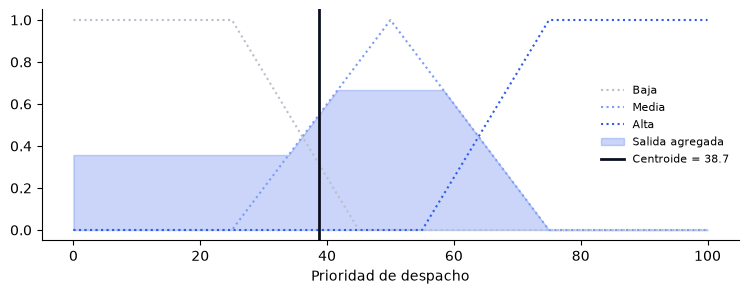

In [8]:
# @title
# CÓDIGO DE APOYO VISUAL (oculto): salida agregada y centroide de Five Sisters
fig, ax = plt.subplots(figsize=(9, 3))
for i, (nombre, p) in enumerate(CONJUNTOS["prioridad"].items()):
    ax.plot(y, trapecio(y, *p), ls=":", color=COLORES[i], label=nombre)
ax.fill_between(y, agregado, color="#2f5bea", alpha=0.25, label="Salida agregada")
ax.axvline(prioridad, color="#0b1020", lw=2, label=f"Centroide = {prioridad:.1f}")
ax.set_xlabel("Prioridad de despacho"); ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False); plt.show()

## Parte 4 — El sistema completo: vetos, queja urgente y lógica difusa

El orden de evaluación respeta la jerarquía del Sprint 2: primero los **vetos** (R4, R5), después la **queja
urgente** (R3) y solo al final el **motor difuso**.

In [9]:
# =============================================================================
# 6. DECISIÓN POR CLIENTE Y POR RUTA
# =============================================================================
TANDA = {"Alta": "ALTA", "Media": "MEDIA"}

def decidir_cliente(cliente):
    h = MEMORIA_TRABAJO[cliente]
    lista_vetos = vetos(h)
    if lista_vetos:
        return {"decision": "EXCLUIDO (veto)", "prioridad": "No aplica", "tanda": "No aplica", "por_que": lista_vetos[0][:60]}
    if h["queja_urgente"]:
        return {"decision": "INCLUIDO", "prioridad": 100.0, "tanda": "ALTA", "por_que": "R3 - Queja urgente"}
    p, etiqueta, act, _ = inferir(entradas_del_cliente(cliente))
    principal = max(act, key=lambda a: a[1])
    return {"decision": "INCLUIDO" if etiqueta in TANDA else "NO ENTRA ESTA SEMANA",
            "prioridad": round(p, 1), "tanda": TANDA.get(etiqueta, "No aplica"),
            "por_que": f"Regla dominante {principal[0]} ({principal[1]:.2f})"}

filas = []
for ruta in RUTAS:
    _, prioridad_exp, detalle_exp = decidir_clientes_de_la_ruta(ruta, MEMORIA_TRABAJO)
    for cliente, datos in CLIENTES.items():
        if datos["ruta"] != ruta:
            continue
        d = decidir_cliente(cliente)
        filas.append({"Ruta": ruta, "Cliente": cliente, **d,
                      "Sprint 2": ("INCLUIDO · " + detalle_exp[cliente]["prioridad"])
                                  if detalle_exp[cliente]["incluir_en_ruta"] else "EXCLUIDO"})
comparacion = pd.DataFrame(filas)
comparacion

,Ruta,Cliente,decision,prioridad,tanda,por_que,Sprint 2
0,Poblado,Fruver del Río,EXCLUIDO (veto),No aplica,No aplica,"R4 (VETO) - El flete ($50,000) es el 5.9% de l...",EXCLUIDO
1,Poblado,Fruver Visitación,NO ENTRA ESTA SEMANA,18.0,No aplica,Regla dominante D10 (1.00),EXCLUIDO
2,Poblado,Five Sisters,INCLUIDO,38.7,MEDIA,Regla dominante D6 (0.67),INCLUIDO · BAJA
3,Poblado,Supermercado Merka 10,INCLUIDO,100.0,ALTA,R3 - Queja urgente,INCLUIDO · ALTA
4,Poblado,Hotel Four Points,NO ENTRA ESTA SEMANA,18.0,No aplica,Regla dominante D10 (1.00),EXCLUIDO
5,Poblado,Mercados Verona,INCLUIDO,52.0,MEDIA,Regla dominante D2 (1.00),INCLUIDO · MEDIA
6,Poblado,EAFIT La Bodeguita,INCLUIDO,100.0,ALTA,R3 - Queja urgente,INCLUIDO · ALTA
7,Poblado,Redetrans,EXCLUIDO (veto),No aplica,No aplica,R5 (VETO) - El punto de venta no ha actualizad...,EXCLUIDO
8,Valle de Aburrá,CEDI Vaquita Itagüí,INCLUIDO,82.0,ALTA,Regla dominante D1 (1.00),INCLUIDO · ALTA
9,Valle de Aburrá,CEDI Euro La Estrella,EXCLUIDO (veto),No aplica,No aplica,"R4 (VETO) - El flete ($95,000) es el 5.3% de l...",EXCLUIDO


In [10]:
# =============================================================================
# 7. DE LA DECISIÓN DIFUSA A LA RUTA (A* del Sprint 1)
# =============================================================================
for ruta in RUTAS:
    sub = comparacion[(comparacion["Ruta"] == ruta) & (comparacion["decision"] == "INCLUIDO")]
    clientes_hoy = list(sub["Cliente"])
    prioridad = dict(zip(sub["Cliente"], sub["tanda"]))
    paradas, km, orden = ruta_de_la_semana(ruta, clientes_hoy, prioridad)

    inc_exp, pri_exp, _ = decidir_clientes_de_la_ruta(ruta, MEMORIA_TRABAJO)
    _, km_exp, orden_exp = ruta_de_la_semana(ruta, inc_exp, pri_exp)

    print("#" * 60); print(f"RUTA {ruta.upper()}"); print("#" * 60)
    print("Difuso  :", orden, f"-> {km:.1f} km")
    print("Sprint 2:", orden_exp, f"-> {km_exp:.1f} km")
    print(" → ".join(paradas)); print()

############################################################
RUTA POBLADO
############################################################
Difuso  : ['EAFIT La Bodeguita', 'Supermercado Merka 10', 'Five Sisters', 'Mercados Verona'] -> 9.4 km
Sprint 2: ['EAFIT La Bodeguita', 'Supermercado Merka 10', 'Mercados Verona', 'Five Sisters'] -> 9.9 km
Bodega Olaya Herrera → Acceso Poblado (Aguacatala) → EAFIT La Bodeguita → Supermercado Merka 10 → Five Sisters → Mercados Verona → Acceso Poblado (Aguacatala) → Plataforma Logística

############################################################
RUTA VALLE DE ABURRÁ
############################################################
Difuso  : ['CEDI Vaquita Itagüí', 'CEDI Supermú'] -> 14.9 km
Sprint 2: ['CEDI Vaquita Itagüí', 'CEDI Supermú'] -> 14.9 km
Bodega Olaya Herrera → Acceso Sur (Itagüí Centro) → CEDI Vaquita Itagüí → Acceso Sur (Itagüí Centro) → CEDI Supermú → Acceso Sur (Itagüí Centro) → Plataforma Logística



## Parte 5 — Sensibilidad: el fin de los umbrales duros

La gráfica muestra la prioridad de un punto de **rotación media** a medida que pasan los días sin entrega, para
cada reporte posible del mercaderista. Con la regla R2 del Sprint 2 la respuesta saltaba de "no entra" a "entra"
en el día 16; con lógica difusa la prioridad crece de forma continua.

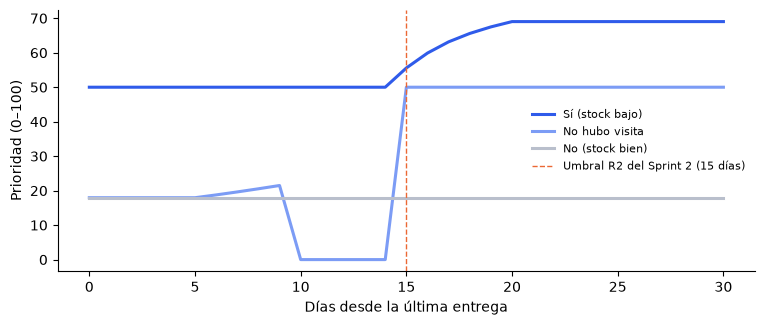

In [11]:
# @title
# CÓDIGO DE APOYO VISUAL (oculto): prioridad vs días sin entrega
dias = np.arange(0, 31)
fig, ax = plt.subplots(figsize=(9, 3.4))
for (nombre, senal), color in zip([("Sí (stock bajo)", 1.0), ("No hubo visita", 0.5), ("No (stock bien)", 0.0)],
                                  ["#2f5bea", "#7c9cf5", "#b9bfcc"]):
    ys = [inferir({"senal_stock": senal, "rotacion": 3.0, "dias_desde_ultima_entrega": d, "flete_pct": 2.0})[0]
          for d in dias]
    ax.plot(dias, ys, lw=2.2, color=color, label=nombre)
ax.axvline(15, color="#eb6834", ls="--", lw=1, label="Umbral R2 del Sprint 2 (15 días)")
ax.set_xlabel("Días desde la última entrega"); ax.set_ylabel("Prioridad (0–100)")
ax.legend(frameon=False, fontsize=8); ax.spines[["top", "right"]].set_visible(False); plt.show()

## Parte 6 — Interpretación y límites

**Lo que cambia frente al Sprint 2**
- Con la memoria de trabajo actual, los **mismos clientes** entran a la ruta: la lógica difusa no contradice al
  sistema experto, lo **refina**. Cambia el orden: Five Sisters (prioridad ≈ 38,7, etiqueta Media) ya no queda en
  la última tanda, y en la ruta Poblado el recorrido baja de 9,9 a 9,4 km.
- Cada cliente tiene ahora un **número comparable** (0–100), no solo una etiqueta. Eso permite ordenar dentro de
  una tanda y explicar qué tan cerca estuvo un cliente de entrar o de salir.
- Desaparecen los saltos por umbral (gráfica de la Parte 5).

**Límites que reconocemos**
- Los parámetros de los trapecios y las reglas son **juicio experto**, no salen de datos. Se calibran con el
  mercaderista; por eso viven en CSV y se pueden ajustar sin tocar código.
- La señal del mercaderista es casi binaria (Sí / No / No hubo visita). El sistema rendiría más con una
  observación graduada (por ejemplo, nivel de góndola de 1 a 5).
- Five Sisters queda en 38,7, muy cerca del cruce Baja/Media (≈ 36): un cambio pequeño en los parámetros la saca
  de la ruta. Es una decisión que el modelo marca como **frontera** y que conviene revisar a mano.
- El orden de visita sigue siendo vecino más cercano por tandas (Sprint 1); no es el óptimo global.

**El agente de IA** (en la app del repositorio) usa estas mismas funciones como herramientas: responde preguntas
como "¿por qué entra Five Sisters?" llamando al motor difuso, sin inventar números.